In [2]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

zsh:1: command not found: wget


In [3]:
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [4]:
print(f"length of dataset in characters: {len(text):,}")

length of dataset in characters: 1,115,394


In [5]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [6]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars) )
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [7]:
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode=lambda s: [stoi[c] for c in s] # take a string, output a list of integers
decode=lambda l: ''.join([itos[i] for i in l]) #take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [13]:
%pip install torch torchvision torchaudio

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 73.6 MB 6.0 MB/s eta 0:00:01
     |████████████████████████████████| 1.9 MB 6.8 MB/s eta 0:00:01
     |████████████████████████████████| 1.9 MB 7.0 MB/s eta 0:00:01
     |████████████████████████████████| 200 kB 6.9 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 13.6 MB/s eta 0:00:01
     |████████████████████████████████| 6.3 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 134 kB 8.1 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 11.2 MB/s eta 0:00:01
     |████████████████████████████████| 5.3 MB 7.1 MB/s eta 0:00:01
     |████████████████████████████████| 536 kB 6.8 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [8]:
import torch
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000])

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

In [9]:
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [10]:
block_size = 8 # how many characters to consider at once
train_data[:block_size+1]

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [11]:
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [12]:
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?

def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)   

for k in range(batch_size):
    for t in range(block_size):
        context = xb[k, :t+1]
        target = yb[k, t]
        print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])
when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] the target: 46
when input is [44, 53, 56,

context available     context model receives<br>
<br>
3 tokens       →      last 3 <br>
6 tokens       →      last 6<br>
8 tokens       →      last 8<br>
20 tokens      →      last 8<br>
100 tokens     →      last 8<br>

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B,T,C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B,T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B,C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B,C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B,1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B,T+1)
        return idx

m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

torch.Size([32, 65])
tensor(4.8786, grad_fn=<NllLossBackward0>)


In [20]:
print(decode(m.generate(idx=torch.zeros((1, 1), dtype=torch.long), max_new_tokens=100)[0].tolist()))


SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


In [21]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)

In [24]:
batch_size = 32
for steps in range(10000):
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(loss.item())

2.373922348022461


In [27]:
print(decode(m.generate(idx=torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))



VI ay,
JO:
NRILAn he asand
HOUn henad anin myod t en!
D otht ofld wher t.
Whe 's fou opepengr.
Fawh y, y Mawin whiand ane, ISpuce. mid-s, mimesewd me tiuclarod

MI wom bentatit h? t s, ss,
Be nrte thosthainelle IAn;
Fokend:

ward aghen
beme t iversu y Ityow bl hong wis thar d ICon, y dat f wimmmyourerdso misthouee'l tes sttallberthe ist ch henofodiefour enget eathathe hinit g:
t th

S:
Ye l acthtof, thopt batr time, cefere; saroutis. s apsere
I a I isious veedit s m the thiny ICEThodut


MENTIN


In [31]:
torch.manual_seed(1337)
B,T,C = 4, 8, 2
x = torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 2])

In [ ]:
xbow = torch.zeros((B,T,C)) #version 1 
for b in range(B):
    for t in range(T):
        xprev = x[b, :t+1] # (t,C)
        xbow[b, t] = torch.mean(xprev, 0)

t = 0 → xprev shape = (1, 4)<br>
t = 1 → xprev shape = (2, 4)<br>
t = 2 → xprev shape = (3, 4)<br>
t = 3 → xprev shape = (4, 4)<br>

In [33]:
x[0]

tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])

In [34]:
xbow[0]

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])

In [35]:
#version 2
torch.manual_seed(1337)
a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)
b = torch.randint(0, 10, (3, 2)).float()
c = a @ b
print('a=', a)
print('b=', b)
print('c=', c)

a= tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
b= tensor([[5., 7.],
        [2., 0.],
        [5., 3.]])
c= tensor([[5.0000, 7.0000],
        [3.5000, 3.5000],
        [4.0000, 3.3333]])


In [38]:
#version 2
wei = torch.tril(torch.ones(T, T))
wei = wei / torch.sum(wei, 1, keepdim=True)
xbow2 = wei @ x
torch.allclose(xbow, xbow2)

True

In [39]:
#versiion 3
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
torch.allclose(xbow, xbow3)

True

A weighted average is an average where some values count more than others.
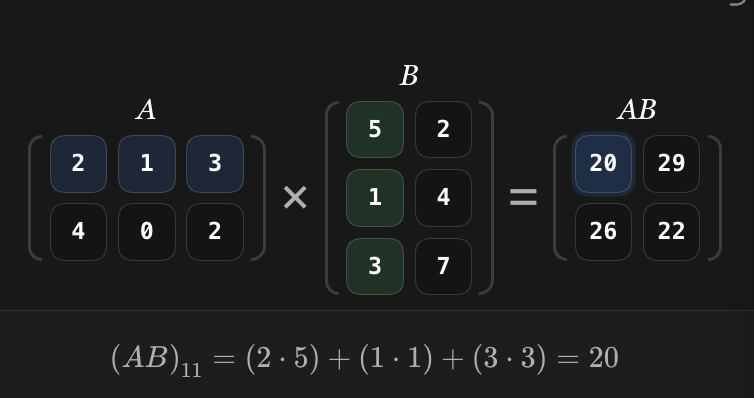


In [60]:
#self attention
torch.manual_seed(1337)
B,T,C = 4, 8, 32
x = torch.randn(B,T,C)  # batch, time, channels

head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B,T,16)
q = query(x) # (B,T,16)
wei = q @ k.transpose(-2, -1) * head_size**-0.5 # (B, T, 16) @ (B, 16, T) -> (B,T,T)

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v

out.shape

torch.Size([4, 8, 16])

In [61]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3966, 0.6034, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3069, 0.2892, 0.4039, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3233, 0.2175, 0.2443, 0.2149, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1479, 0.2034, 0.1663, 0.1455, 0.3369, 0.0000, 0.0000, 0.0000],
        [0.1259, 0.2490, 0.1324, 0.1062, 0.3141, 0.0724, 0.0000, 0.0000],
        [0.1598, 0.1990, 0.1140, 0.1125, 0.1418, 0.1669, 0.1061, 0.0000],
        [0.0845, 0.1197, 0.1078, 0.1537, 0.1086, 0.1146, 0.1558, 0.1553]],
       grad_fn=<SelectBackward0>)

Query = “What am I looking for?”<br>
Key = “What kind of information do I contain?”<br>
Value = “What actual information should I give you if you attend to me?”<br>

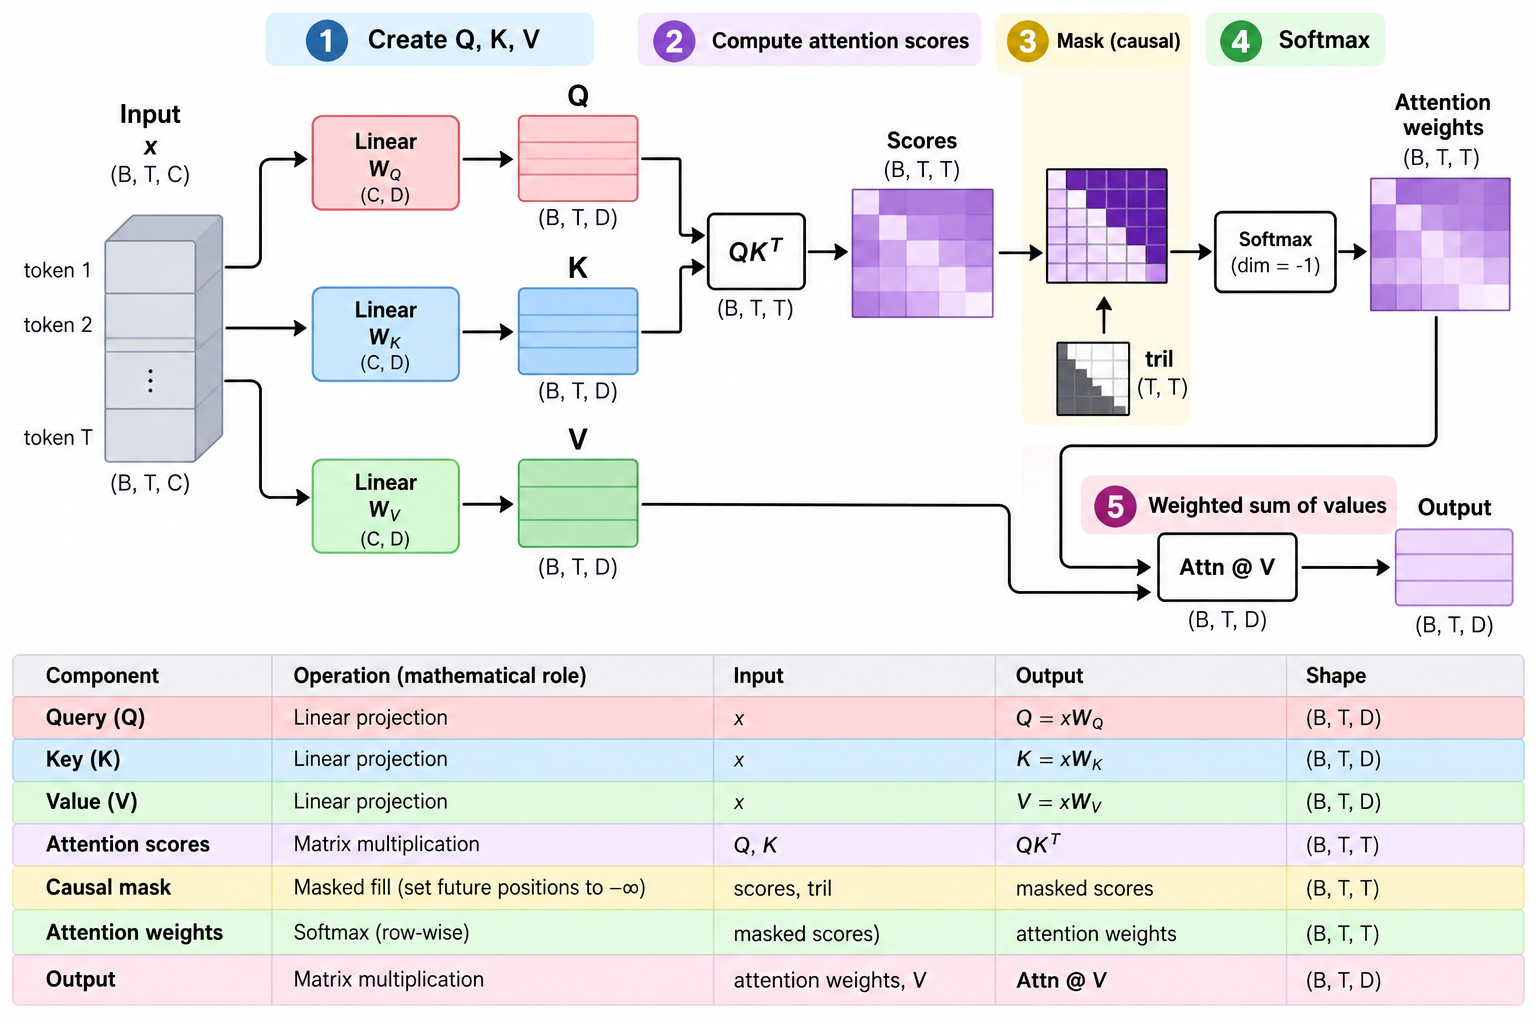

During training, self-attention produces a new vector for each token by taking a weighted sum of the value vectors. This is an intermediate representation, not a predicted token. It passes through the remaining model layers, and a final linear layer produces scores over the vocabulary. Cross-entropy loss measures how well these scores predict the correct next token. Backpropagation then uses the chain rule to calculate how each trainable parameter affects that loss—we do not have to identify whether the mistake came from queries, keys, or values. Gradients flow through both sides of the attention multiplication: through values to the value projection, and through attention weights, softmax, and attention scores to the query and key projections. Each projection receives its own gradients from the same loss. After backpropagation, the optimizer updates the trainable parameters throughout the model, not just those three projections. There are no parameter updates between the attention stages. During ordinary generation, the learned parameters remain fixed, while new inputs produce new vectors and attention weights.

In [53]:
k= torch.randn(B,T, head_size)
q= torch.randn(B,T, head_size)
wei = q @ k.transpose(-2, -1) 

In [54]:
k.var()

tensor(1.0966)

In [55]:
wei.var()

tensor(16.1036)

In [56]:
wei[0]

tensor([[-7.3737e-01, -4.5764e+00, -5.9989e-01,  5.1103e-01, -5.7737e+00,
          4.2391e+00,  6.0750e+00, -8.1254e-01],
        [ 7.0977e+00, -1.3900e+00,  3.8604e+00,  6.8851e-01, -8.1158e+00,
         -1.3494e+00, -5.9063e+00, -8.9052e+00],
        [ 5.9575e+00, -6.3387e+00, -1.5576e+00,  2.2627e+00, -1.2760e+00,
          2.1324e+00, -1.9577e+00,  5.2438e+00],
        [-1.0962e-01,  1.3197e+00,  3.3976e-01,  2.0967e+00,  4.2496e+00,
         -2.6100e+00,  2.5769e+00,  5.0928e+00],
        [-3.1138e+00, -3.0760e+00,  4.4032e-01,  2.5606e+00, -6.2666e+00,
          3.4692e+00,  3.0697e+00, -1.7509e+00],
        [-4.5324e+00,  7.1474e+00,  4.6307e+00, -4.4207e+00,  6.7780e+00,
         -1.7787e+00, -4.3983e-01,  3.4903e+00],
        [ 2.4796e+00,  4.9593e+00,  3.3423e+00, -6.9203e+00, -8.6290e-01,
          1.7273e+00, -6.1709e+00,  6.2957e+00],
        [ 1.6635e+00,  1.0610e+00,  8.4995e+00, -6.6346e-01, -1.0209e+01,
          3.3386e+00, -2.5702e+00,  1.9313e-03]])

In [57]:
k= torch.randn(B,T, head_size)
q= torch.randn(B,T, head_size)
wei2 = q @ k.transpose(-2, -1) * head_size**-0.5

In [58]:
wei2.var()

tensor(1.1053)

In [59]:
wei2[0]

tensor([[-0.1317, -0.1243, -0.2252,  2.8750,  1.9908,  2.2064,  1.0299, -2.7707],
        [-0.8395, -1.6099, -0.3788, -0.1000, -1.5721, -1.0171,  1.1354,  0.9972],
        [ 0.5273,  0.3083,  0.5947,  0.1936,  1.0412,  0.4417, -0.3327,  0.0186],
        [-0.2433,  0.9809, -0.6502,  0.9964, -0.1054,  0.2572, -0.3070, -2.3429],
        [ 1.2891,  0.3465,  1.4765, -3.1106, -1.7038, -0.5902, -0.9278,  1.1591],
        [ 0.5801,  0.4069,  0.5060,  1.5214,  0.1991,  0.2683, -0.7221,  2.2640],
        [-2.5122, -0.0736, -0.9311, -0.5938, -0.2786, -0.4678, -0.4031, -0.4771],
        [-0.2626, -1.2887,  0.7124,  0.8077, -0.6197, -1.3085, -0.7532,  1.9045]])